=== RINGKASAN DESKRIPTIF KATALOG GEMPABUMI ===
Rentang Waktu: 2021-01-01 00:00:00 s.d. 2022-03-26 00:00:00
Total Kejadian: 450 event
Batas Lintang: -7.98° hingga 1.99°
Batas Bujur: 100.02° hingga 129.87°

Statistik Parameter Dasar:
       Kedalaman_km   Magnitudo
count    450.000000  450.000000
mean      35.523336    5.607375
std       33.670153    0.921660
min        0.193483    4.021411
25%       10.301432    4.793222
50%       26.700314    5.604370
75%       50.116249    6.391778
max      178.044622    7.198605


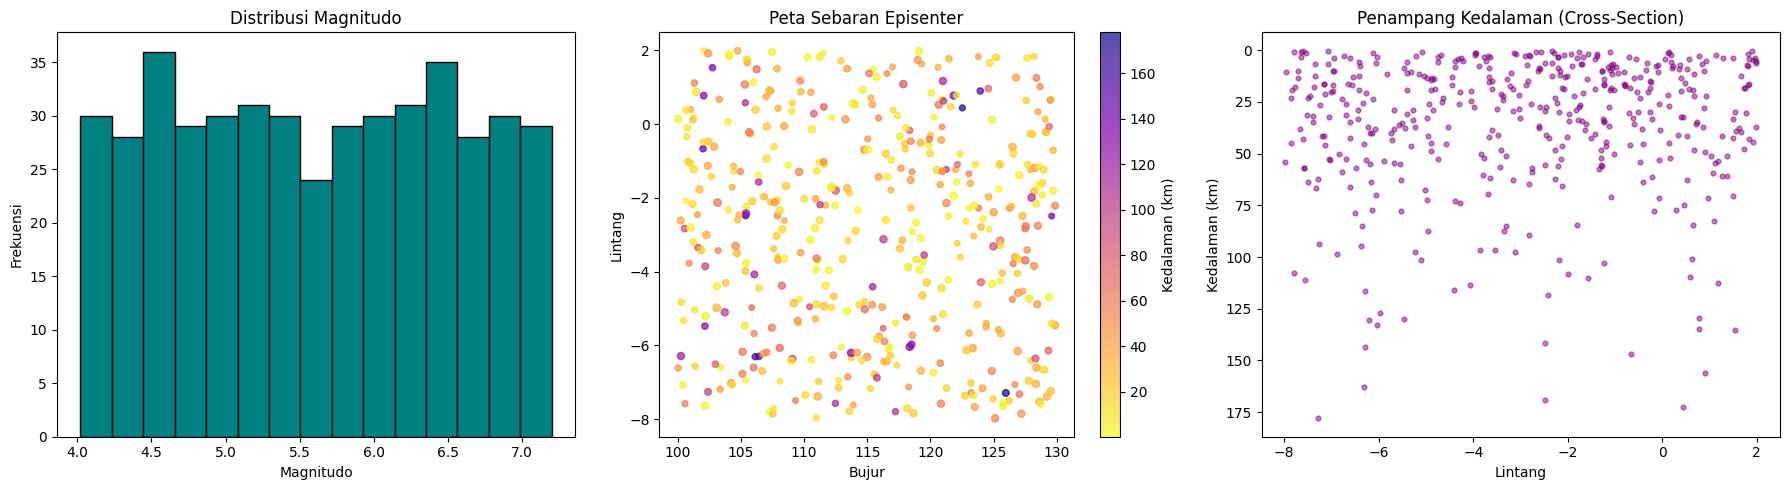

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Simulasi Dataset Katalog Gempabumi
np.random.seed(1074)
n_events = 450
df_gempa = pd.DataFrame({
    'Waktu': pd.date_range(start='2021-01-01', periods=n_events, freq='D'),
    'Lintang': np.random.uniform(-8.0, 2.0, n_events),
    'Bujur': np.random.uniform(100.0, 130.0, n_events),
    'Kedalaman_km': np.random.exponential(scale=35.0, size=n_events),
    'Magnitudo': np.random.uniform(4.0, 7.2, n_events),
})

# 1. Ringkasan Deskriptif Katalog
print('=== RINGKASAN DESKRIPTIF KATALOG GEMPABUMI ===')
print(f'Rentang Waktu: {df_gempa["Waktu"].min()} s.d. {df_gempa["Waktu"].max()}')
print(f'Total Kejadian: {len(df_gempa)} event')
print(f'Batas Lintang: {df_gempa["Lintang"].min():.2f}° hingga {df_gempa["Lintang"].max():.2f}°')
print(f'Batas Bujur: {df_gempa["Bujur"].min():.2f}° hingga {df_gempa["Bujur"].max():.2f}°')
print('\nStatistik Parameter Dasar:')
print(df_gempa[['Kedalaman_km', 'Magnitudo']].describe())

# 2. Visualisasi Grafik & Peta Episenter
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram Magnitudo
axes[0].hist(df_gempa['Magnitudo'], bins=15, color='teal', edgecolor='black')
axes[0].set_title('Distribusi Magnitudo')
axes[0].set_xlabel('Magnitudo')
axes[0].set_ylabel('Frekuensi')

# Peta Sebaran Episenter
sc = axes[1].scatter(
    df_gempa['Bujur'],
    df_gempa['Lintang'],
    c=df_gempa['Kedalaman_km'],
    cmap='plasma_r',
    s=df_gempa['Magnitudo'] * 4,
    alpha=0.7,
)
axes[1].set_title('Peta Sebaran Episenter')
axes[1].set_xlabel('Bujur')
axes[1].set_ylabel('Lintang')
plt.colorbar(sc, ax=axes[1], label='Kedalaman (km)')

# Penampang Kedalaman (Lintang vs Kedalaman)
axes[2].scatter(
    df_gempa['Lintang'],
    df_gempa['Kedalaman_km'],
    c='purple',
    alpha=0.5,
    s=12,
)
axes[2].set_title('Penampang Kedalaman (Cross-Section)')
axes[2].set_xlabel('Lintang')
axes[2].set_ylabel('Kedalaman (km)')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

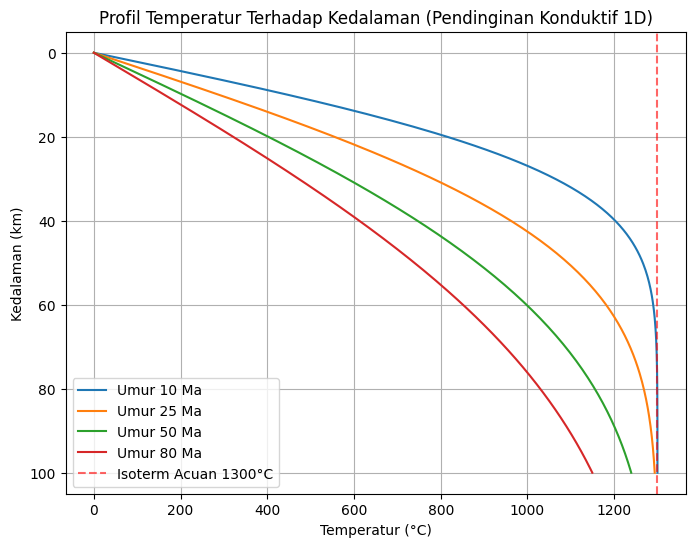

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erf

# Parameter Fisika Litosfer Samudera
T_surface = 0.0      # Suhu permukaan (°C)
T_mantle = 1300.0    # Suhu mantel/astenosfer (°C)
kappa = 8.0e-7       # Difusivitas termal (m^2/s)
sec_in_myr = 1e6 * 365.25 * 24 * 3600  # Konversi Ma ke detik

# Kedalaman z dari 0 hingga 100 km (dalam meter)
z = np.linspace(0, 100000, 200)
ages_ma = [10, 25, 50, 80]

plt.figure(figsize=(8, 6))

for age in ages_ma:
  t = age * sec_in_myr
  # Solusi Analitik Half-Space Cooling Model
  T = T_surface + (T_mantle - T_surface) * erf(z / (2 * np.sqrt(kappa * t)))
  plt.plot(T, z / 1000, label=f'Umur {age} Ma')

plt.title('Profil Temperatur Terhadap Kedalaman (Pendinginan Konduktif 1D)')
plt.xlabel('Temperatur (°C)')
plt.ylabel('Kedalaman (km)')
plt.gca().invert_yaxis()
plt.axvline(1300, color='red', linestyle='--', alpha=0.6, label='Isoterm Acuan 1300°C')
plt.legend()
plt.grid(True)
plt.show()

=== PARAMETER MODEL VARIOGRAM ===
Nugget Effect : 0.0000
Sill          : 1.1485
Range         : 65.2290 km


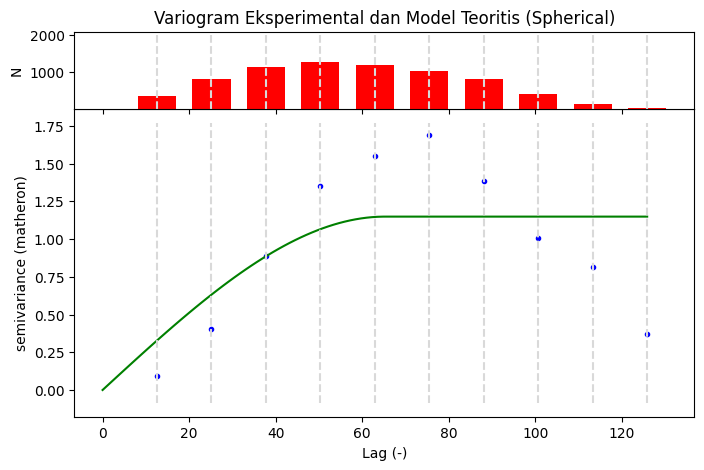

In [7]:
!pip install scikit-gstat

import matplotlib.pyplot as plt
import numpy as np
import skgstat as skg

# Simulasi Data Spasial Titik Pengukuran Geofisika (Koordinat X, Y dan Atribut Nilai)
np.random.seed(1074)
coords = np.random.rand(120, 2) * 100  # Koordinat dalam kilometer
values = np.cos(coords[:, 0] / 15) + np.sin(coords[:, 1] / 15) + np.random.normal(0, 0.1, 120)

# Menghitung Variogram Eksperimental
V = skg.Variogram(coords, values, estimator='matheron', n_lags=10, model='spherical')

# Pada scikit-gstat terbaru, parameter model teoritis dapat diperoleh dari properti .parameters
# Urutan standarnya adalah: [range, sill, nugget]
params = V.parameters
var_range = params[0]
var_sill = params[1]
var_nugget = params[2]

print('=== PARAMETER MODEL VARIOGRAM ===')
print(f'Nugget Effect : {var_nugget:.4f}')
print(f'Sill          : {var_sill:.4f}')
print(f'Range         : {var_range:.4f} km')

# Plot Variogram Eksperimental & Model Teoritis
V.plot()
plt.title('Variogram Eksperimental dan Model Teoritis (Spherical)')
plt.show()

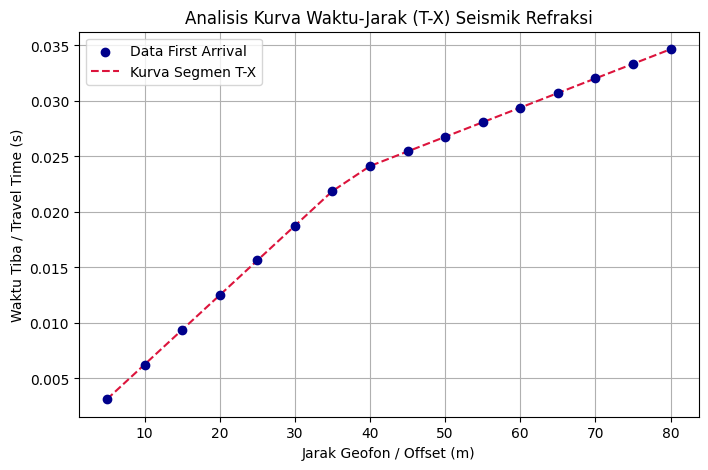

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Parameter Data Seismik Refraksi
jarak_x = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80])
v1 = 1600.0  # Kecepatan gelombang lapisan 1 (m/s)
v2 = 3800.0  # Kecepatan gelombang lapisan 2 (m/s)
h1 = 12.0    # Estimasi ketebalan lapisan pertama (m)

# Perhitungan Waktu Tempuh First Arrival (Gelombang Langsung & Biasan)
crossover_distance = 2 * h1 * np.sqrt((v2 + v1) / (v2 - v1))
waktu_t = np.where(
    jarak_x < crossover_distance,
    jarak_x / v1,
    (jarak_x / v2) + (2 * h1 * np.sqrt(v2**2 - v1**2) / (v1 * v2))
)

# Plot Grafik Waktu-Jarak (T-X)
plt.figure(figsize=(8, 5))
plt.scatter(jarak_x, waktu_t, color='darkblue', label='Data First Arrival', zorder=3)
plt.plot(jarak_x, waktu_t, color='crimson', linestyle='--', label='Kurva Segmen T-X', zorder=2)
plt.title('Analisis Kurva Waktu-Jarak (T-X) Seismik Refraksi')
plt.xlabel('Jarak Geofon / Offset (m)')
plt.ylabel('Waktu Tiba / Travel Time (s)')
plt.grid(True)
plt.legend()
plt.show()

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# 1. Simulasi Dataset Log Sumur
np.random.seed(1074)
n_samples = 1200
df_log = pd.DataFrame({
    'Well_ID': np.random.choice(['Sumur_Alpha', 'Sumur_Beta', 'Sumur_Gamma', 'Sumur_Delta'], n_samples),
    'Depth': np.sort(np.random.uniform(500, 3000, n_samples)),
    'Gamma_Ray': np.random.uniform(15, 160, n_samples),
    'Density': np.random.uniform(1.9, 2.7, n_samples),
    'Sonic': np.random.uniform(45, 135, n_samples),
})

# Pelabelan Litologi Sintetik Berdasarkan Atribut Log Fisika Batuan
conds = [
    (df_log['Gamma_Ray'] < 55) & (df_log['Density'] > 2.4),
    (df_log['Gamma_Ray'] >= 55) & (df_log['Gamma_Ray'] < 95),
    (df_log['Gamma_Ray'] >= 95),
]
classes = ['Batugamping', 'Batupasir', 'Serpih']
df_log['Litologi'] = np.select(conds, classes, default='Batupasir')

# 2. Seleksi Fitur (Atribut kedalaman & ID sumur TIDAK digunakan sebagai fitur masukan)
X = df_log[['Gamma_Ray', 'Density', 'Sonic']]
y = df_log['Litologi']

# 3. Pembagian Data Berbasis Sumur (Well-based split untuk mencegah data leakage)
train_w, test_w = train_test_split(df_log['Well_ID'].unique(), test_size=0.25, random_state=1074)
train_mask = df_log['Well_ID'].isin(train_w)
test_mask = ~train_mask

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

# 4. Pelatihan Model Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, random_state=1074)
rf_clf.fit(X_train, y_train)

# 5. Evaluasi Performa Model
y_pred = rf_clf.predict(X_test)
print('=== LAPORAN EVALUASI KLASIFIKASI LITOLOGI (RANDOM FOREST) ===')
print(classification_report(y_test, y_pred))

=== LAPORAN EVALUASI KLASIFIKASI LITOLOGI (RANDOM FOREST) ===
              precision    recall  f1-score   support

 Batugamping       1.00      1.00      1.00        29
   Batupasir       1.00      1.00      1.00       125
      Serpih       1.00      1.00      1.00       124

    accuracy                           1.00       278
   macro avg       1.00      1.00      1.00       278
weighted avg       1.00      1.00      1.00       278

